In [1]:
# === Google Colab 自動環境セットアップ ===
# ※ローカル環境では安全に無視され、Colab環境でのみ自動実行されます
import os, sys
repo_root = os.path.abspath(os.path.join(os.getcwd(), "..")) if os.path.exists("../common") else os.path.abspath(os.getcwd())
if "google.colab" in sys.modules:
    print("⚡ Google Colab 環境を検出しました。リポジトリのセットアップを開始します...")
    !git clone https://github.com/miyayudai/study-mikanos.git /content/study-mikanos 2>/dev/null || (cd /content/study-mikanos && git pull)
    %cd /content/study-mikanos
    !pip install -q matplotlib pytest numpy
    repo_root = "/content/study-mikanos"
    sys.path.insert(0, repo_root)
    print("✅ 環境セットアップが完了しました。作業ディレクトリ:", os.getcwd())
else:
    if repo_root not in sys.path:
        sys.path.insert(0, repo_root)
    os.chdir(repo_root)
    print("💻 ローカル開発環境を検出しました。作業ディレクトリ:", os.getcwd())


💻 ローカル開発環境を検出しました。作業ディレクトリ: /home/student/Documents/GitHub/study-mikanos


# 8.6 ページングの設定 (`osbook_day08b` / `day08c`)

本節では、名著『ゼロからのOS自作入門』第8章「メモリ管理」における最重要ハードウェア制御の一つである**「4階層ページング（4-Level Paging Architecture）」**の理論導出、**2MiB Huge Page による 64GiB 恒等マッピング（Identity Mapping）**の設計、および **CR3 レジスタ設定**による CPU 仮想記憶機構の掌握を徹底的に探究します。

---

## 🎯 本節の学習到達目標

1. **OS 自前でページングを設定する動機と必然性**:
   - なぜ UEFI 任せのページテーブルではいけないのか？
   - x86-64 Long Mode における CPU 仕様としてのページング必須要件（`CR0.PG = 1`）
   - UEFI 管理領域にあるページテーブルの危険性と、将来の空間分離（ユーザー空間 Ring 3 とカーネル空間 Ring 0）への礎石
2. **x86-64 の 4階層ページング（4-Level Paging）アーキテクチャの完全理解**:
   - 48ビット正規仮想アドレス（Canonical Address）の構造（Sign Extension と `9 + 9 + 9 + 9 + 12` 分解）
   - PML4 (*Page Map Level 4*), PDP (*Page Directory Pointer*), PD (*Page Directory*), PT (*Page Table*) の階層的探索モデル
   - 4KiB アライメント制約（`alignas(4096)`）と下位 12 ビットフラグ活用のメカニズム
3. **2MiB Huge Page（ラージページ）による 64GiB 恒等マッピング（Identity Mapping）**:
   - 標準 4KiB ページを用いた場合の莫大なテーブルメモリ消費（128 MiB）と TLB ミスペナルティ
   - PD エントリのビット 7（`PS = 1`, Page Size）による PT 省略と 2MiB 直結マッピング
   - たった 64 個の PD（264 KiB）で 64GiB 物理空間をカバーする驚異的なメモリ節約（485倍の削減効果）
4. **エントリビットマスクと CR3 レジスタ設定**:
   - ポインタフラグ `0x003`（Present=1, Read/Write=1）と 2MiB ページフラグ `0x083`（Present=1, Read/Write=1, PageSize=1）の導出
   - CR3 レジスタ（*Page Directory Base Register*, PDBR）への PML4 ベースアドレス書き込みと自動 TLB フラッシュ動作
5. **C++20 & Python ハイブリッド検証**:
   - MikanOS `kernel/paging.hpp` / `paging.cpp` の完全行単位解説
   - ホスト環境 C++20 での実装・動作検証と、Python シミュレータによる 64GiB アドレス変換実験


---

## 1. なぜ OS 自前でページングを設定する必要があるのか？

### 1.1 x86-64 Long Mode のハードウェア不変条件 (`CR0.PG = 1`)
Intel/AMD の 64ビット CPU アーキテクチャ（x86-64 / AMD64）では、**ロングモード（Long Mode）で動作している間、ページング機構を無効化（`CR0.PG = 0`）することは CPU 仕様上絶対に許されません**。
ロングモード有効化（`IA32_EFER.LME = 1`）後、制御レジスタ `CR0` のページング有効化ビット（ビット 31: `PG`）を 1 に設定することで、初めて CPU は 64ビットモードへ移行します。

第1章〜第7章まで、我々のカーネルはページングのコードを 1 行も書いていないにもかかわらず問題なく動作していました。これはなぜでしょうか？
それは、**UEFI BIOS ファームウェアが起動時に独自のページテーブルを構築し、CR3 レジスタにセットした状態でカーネルを呼び出していたから**です。

### 1.2 UEFI 任せのページテーブルが抱える 3 つの致命的リスク
前節（8.3節・8.4節）で学んだデータ構造やスタックの退避と全く同様に、UEFI が作ったページテーブルを使い続けることには以下の深刻な問題があります：

```
+-----------------------------------------------------------------------------------+
| UEFI Firmware 管理メモリ (EfiBootServicesData / EfiConventionalMemory)            |
|   ┌─────────────────────────────────────────────────────────────┐                 |
|   │ UEFI 独自のページテーブル (PML4, PDP, PD, PT)               │                 |
|   │ ⚠️ ExitBootServices() 後、カーネルがメモリを再利用すると自滅 │                 |
|   └─────────────────────────────────────────────────────────────┘                 |
+-----------------------------------------------------------------------------------+
                                      ▲
                           CR3 レジスタが指している
                                      │
+─────────────────────────────────────┴─────────────────────────────────────────────+
| MikanOS カーネル (.text / .data / .bss)                                            |
|   いつページテーブルが破壊されるかわからない極めて不安定な状態！                   |
+-----------------------------------------------------------------------------------+
```

1. **メモリ破壊による CPU クラッシュの危険**:
   - UEFI のページテーブルはファームウェアの作業用メモリ領域に配置されています。カーネルが将来 `BitmapMemoryManager` 等でメモリを割り当てて使用すると、**カーネル自身が自分を動かしているページテーブルを上書きしてしまい、即座にトリプルフォルト（CPU リセット再起動）を引き起こします**。
2. **マッピング範囲の不確定性**:
   - UEFI 実装（OVMF や各種 PC ベンダーの BIOS）によって、初期状態でマッピングされている物理メモリ範囲が 2GiB だったり 4GiB だったりとバラバラです。4GiB を超える大容量 RAM や VRAM（MMIO 領域）にアクセスした瞬間にページフォルト（#PF）で停止する危険があります。
3. **特権分離・プロセス仮想アドレス空間への拡張不可**:
   - 第19章・第20章で導入する「アプリごとの独立した仮想記憶空間（プロセス分離）」や「Ring 3（ユーザーモード）と Ring 0（カーネルモード）の保護」を実現するためには、OS 自身がページテーブルの全エントリを完全に掌握・制御していなければなりません。

したがって、**カーネルの静的メモリ領域（`.bss`）にカーネル専用のページテーブルを新規構築し、CR3 レジスタを自前のテーブルに切り替えること**が、自作 OS の生命線となるのです。


---

## 2. x86-64 4階層ページングの数理とビット構造

### 2.1 48ビット正規仮想アドレス（Canonical Address）の構造
x86-64 アーキテクチャの仮想アドレスは 64 ビット幅を持ちますが、現行の多くの CPU 実装（5階層ページング拡張以前）では **下位 48 ビット** がリニアアドレス（仮想アドレス）として使用されます。
上位 16 ビット（ビット 63〜48）は、**ビット 47 の符号拡張（Sign Extension）**でなければならないという厳格なハードウェア規則が存在します。これを**正規アドレス（Canonical Address）**と呼びます。

- **ユーザー空間（前半）**: ビット 47 が `0` $\rightarrow$ 上位 16 ビットはすべて `0x0000`（`0x0000_0000_0000_0000` 〜 `0x0000_7FFF_FFFF_FFFF`：128 TiB）
- **カーネル空間（後半）**: ビット 47 が `1` $\rightarrow$ 上位 16 ビットはすべて `0xFFFF`（`0xFFFF_8000_0000_0000` 〜 `0xFFFF_FFFF_FFFF_FFFF`：128 TiB）
- **非正規アドレス（Non-canonical Address）**: 上位 16 ビットがビット 47 と一致しないアドレス。CPU がアクセスすると即座に一般保護例外（#GP: General Protection Fault）が発生します。

下位 48 ビットは、以下のように **9ビット $\times$ 4階層 ＋ 12ビット オフセット** に綺麗に分割されます：

$$\text{Linear Address (48-bit)} = \underbrace{\text{PML4}[47:39]}_{9\text{ bits}} \;\Vert\; \underbrace{\text{PDP}[38:30]}_{9\text{ bits}} \;\Vert\; \underbrace{\text{PD}[29:21]}_{9\text{ bits}} \;\Vert\; \underbrace{\text{PT}[20:12]}_{9\text{ bits}} \;\Vert\; \underbrace{\text{Offset}[11:0]}_{12\text{ bits}}$$

各インデックスが 9 ビットである理由は極めて明快です：
$$2^9 = 512 \text{ エントリ}$$
各エントリのサイズは 64 ビット（8 バイト）なので、
$$512 \times 8 \text{ バイト} = 4,096 \text{ バイト} = 4 \text{ KiB}$$
すなわち、**どの階層のページテーブルも「ちょうど 1 ページフレーム（4 KiB）」にピッタリ収まる**ように極めて美しく設計されているのです！


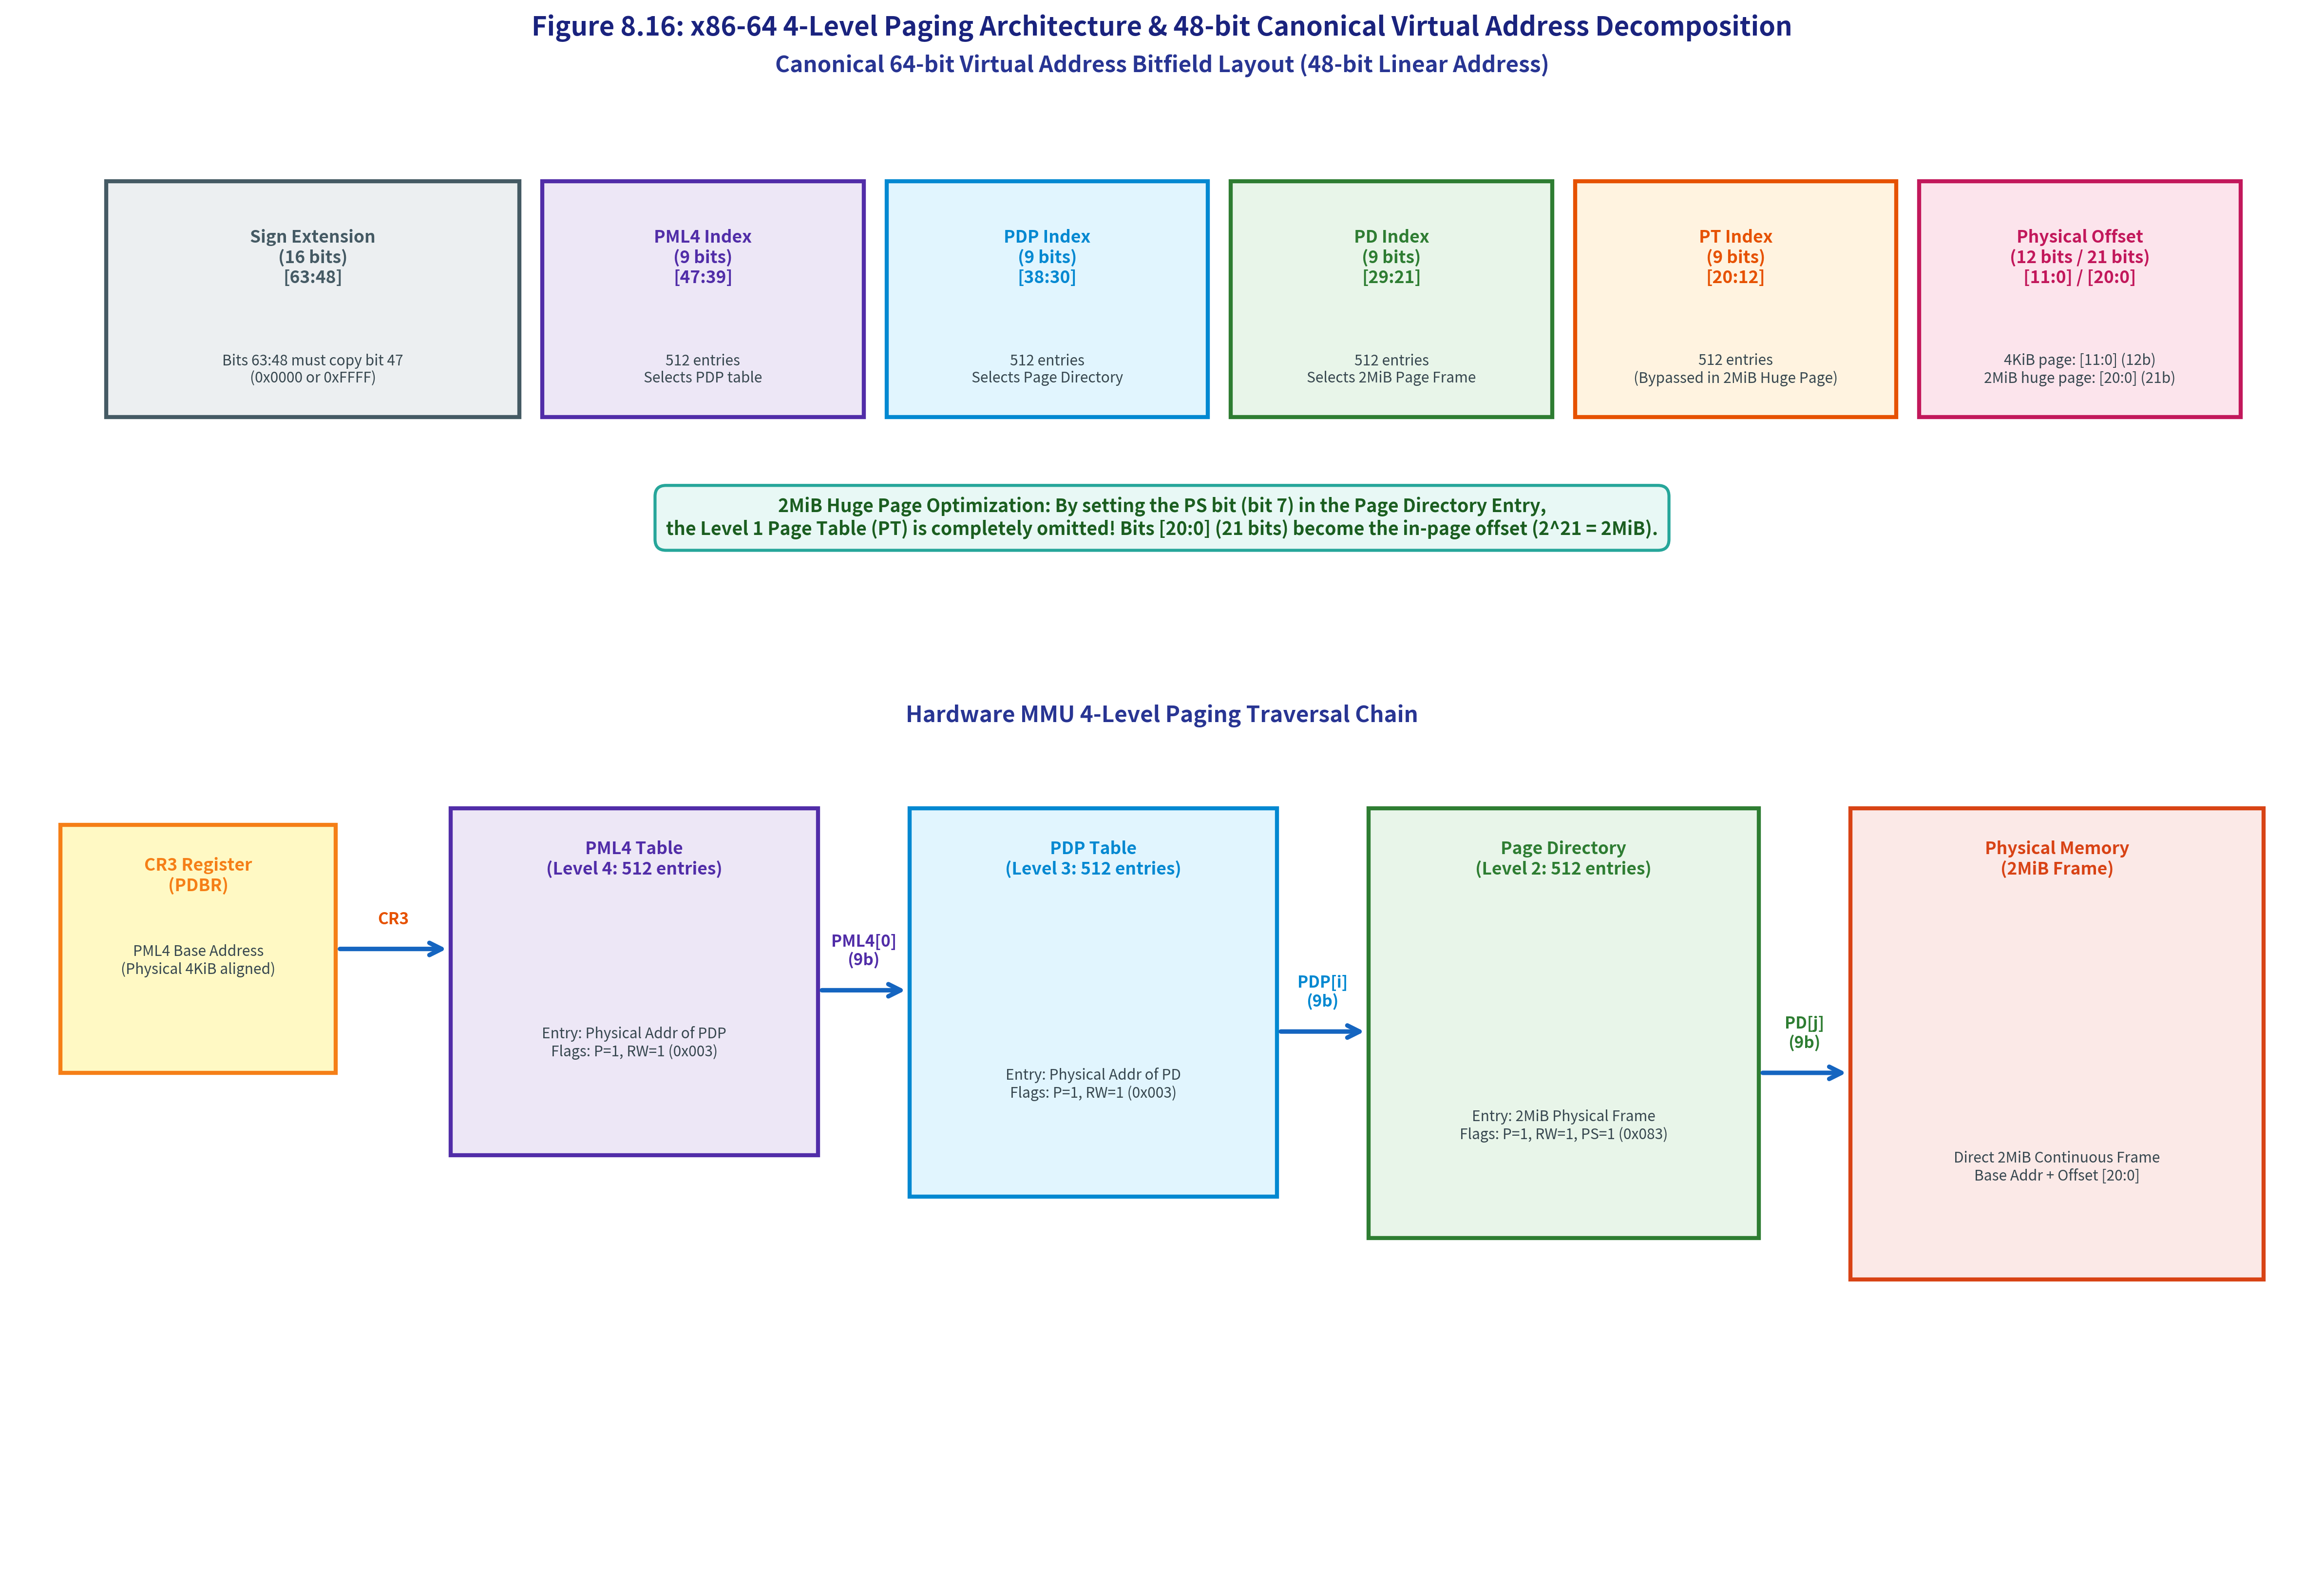

In [2]:
# 図版 8.16: x86-64 4階層ページングアーキテクチャと正規仮想アドレス分解の生成
from common.os_sim import plot_fig8_16_x86_64_4level_paging_architecture
from IPython.display import Image, display

fig8_16_path = plot_fig8_16_x86_64_4level_paging_architecture()
display(Image(filename=fig8_16_path))


### 図版 8.16 の解説: ハードウェア MMU による 4 段階探索シーケンス

上図は、CPU のメモリ管理ユニット（MMU: *Memory Management Unit*）が仮想アドレスを物理アドレスに変換するハードウェア動作の全貌を示しています：

1. **CR3 レジスタ (PDBR: *Page Directory Base Register*)**:
   - PML4 テーブルの先頭物理アドレスを保持します。下位 12 ビットは 0（4KiB アライメント）である必要があります。
2. **Level 4: PML4 (Page Map Level 4 Table)**:
   - 仮想アドレスの `[47:39]`（9ビット）でインデックスされ、対応する PDP テーブルの物理アドレスを取得します。
3. **Level 3: PDP (Page Directory Pointer Table)**:
   - 仮想アドレスの `[38:30]`（9ビット）でインデックスされ、対応する Page Directory の物理アドレスを取得します。
4. **Level 2: PD (Page Directory Table)**:
   - 仮想アドレスの `[29:21]`（9ビット）でインデックスされます。
   - **4KiB ページの場合**: Level 1 Page Table (PT) の物理アドレスを取得。
   - **2MiB Huge Page の場合 (MikanOS)**: ここで探索が完了！2MiB 物理ページフレームのベースアドレスを取得します。
5. **Level 1: PT (Page Table)**:
   - 通常の 4KiB ページングの場合のみ使用され、最終的な 4KiB 物理ページフレームアドレスを取得します。


---

## 3. 2MiB Huge Page（ラージページ）と 64GiB 恒等マッピング

### 3.1 4KiB ページ方式の限界：莫大なテーブル消費
もし MikanOS が 64GiB の物理アドレス空間を標準の 4KiB ページ単位でマッピングしようとすると何が起きるでしょうか？

- **64 GiB に含まれる 4KiB ページの総数**:
  $$\frac{64 \times 1024^3 \text{ B}}{4096 \text{ B}} = 16,777,216 \text{ ページ} (1600\text{万ページ})$$
- **必要となる Level 1 Page Table (PT) の個数**:
  1 つの PT は 512 個の 4KiB ページを管理できるため、
  $$\frac{16,777,216}{512} = 32,768 \text{ テーブル}$$
- **ページテーブルだけで消費されるメモリ量**:
  $$32,768 \times 4096 \text{ バイト} = 134,217,728 \text{ バイト} \approx \mathbf{128 \text{ MiB}} !$$

カーネルの起動初期（まだ動的メモリアロケータすらない段階）で、ページテーブルのためだけに 128 MiB もの連続メモリを確保することは到底不可能です。

### 3.2 2MiB Huge Page による奇跡的な最適化
x86-64 アーキテクチャには、**Page Directory Entry (PDE) のビット 7（`PS`: Page Size）を 1 にセットすることで、Level 1 Page Table (PT) を丸ごとバイパスし、PD から直接 2MiB の連続物理フレームをマッピングできる機構**が備わっています！

2MiB ページを使う場合、仮想アドレスの下位 21 ビット（$2^{21} = 2,097,152 = 2\text{ MiB}$）がそのままページ内オフセットとなります：

$$\text{Linear Address (2MiB Page)} = \underbrace{\text{PML4}[47:39]}_{9\text{ bits}} \;\Vert\; \underbrace{\text{PDP}[38:30]}_{9\text{ bits}} \;\Vert\; \underbrace{\text{PD}[29:21]}_{9\text{ bits}} \;\Vert\; \underbrace{\text{Offset}[20:0]}_{21\text{ bits (2MiB)}}$$

これによってテーブル構造は劇的に簡素化されます：
1. **1 つの Page Directory (PD)**:
   $$512 \text{ エントリ} \times 2 \text{ MiB} = 1,024 \text{ MiB} = \mathbf{1 \text{ GiB}}$$
2. **64 GiB をマッピングするために必要な PD の個数**:
   $$\frac{64 \text{ GiB}}{1 \text{ GiB}} = \mathbf{64 \text{ 個}} (\texttt{kPageDirectoryCount} = 64)$$
3. **必要な全ページテーブルのメモリ消費量**:
   - PML4 テーブル: 1 個 (4 KiB)
   - PDP テーブル: 1 個 (4 KiB)
   - PD テーブル: 64 個 ($64 \times 4 \text{ KiB} = 256 \text{ KiB}$)
   - **合計メモリ**: $4 + 4 + 256 = \mathbf{264 \text{ KiB}} \quad (\text{約 } 0.26 \text{ MiB})$

**128 MiB から 264 KiB へ、実に 485 倍（99.8% 削減）の劇的なメモリ軽量化**が達成されます！
264 KiB であれば、カーネルの `.bss` 領域に静的配列として余裕で埋め込むことができます。

### 3.3 恒等マッピング（Identity Mapping / 1対1マッピング）の意義
**恒等マッピング**とは、任意の仮想アドレス $V$ に対して、変換先の物理アドレス $P$ が完全に同一（$V = P$）となるページテーブル設定を指します。
起動直後のカーネルは、UEFI がメモリ上にロードしたコードやスタックのアドレスを直接ポインタとして使っています。恒等マッピングを設定して CR3 を切り替えれば、**命令ポインタ（RIP）やスタックポインタ（RSP）が指すアドレスの意味が一切変わらないため、CPU を 1 クロックの中断もなくシームレスに新ページテーブルへ移行**させることができるのです。


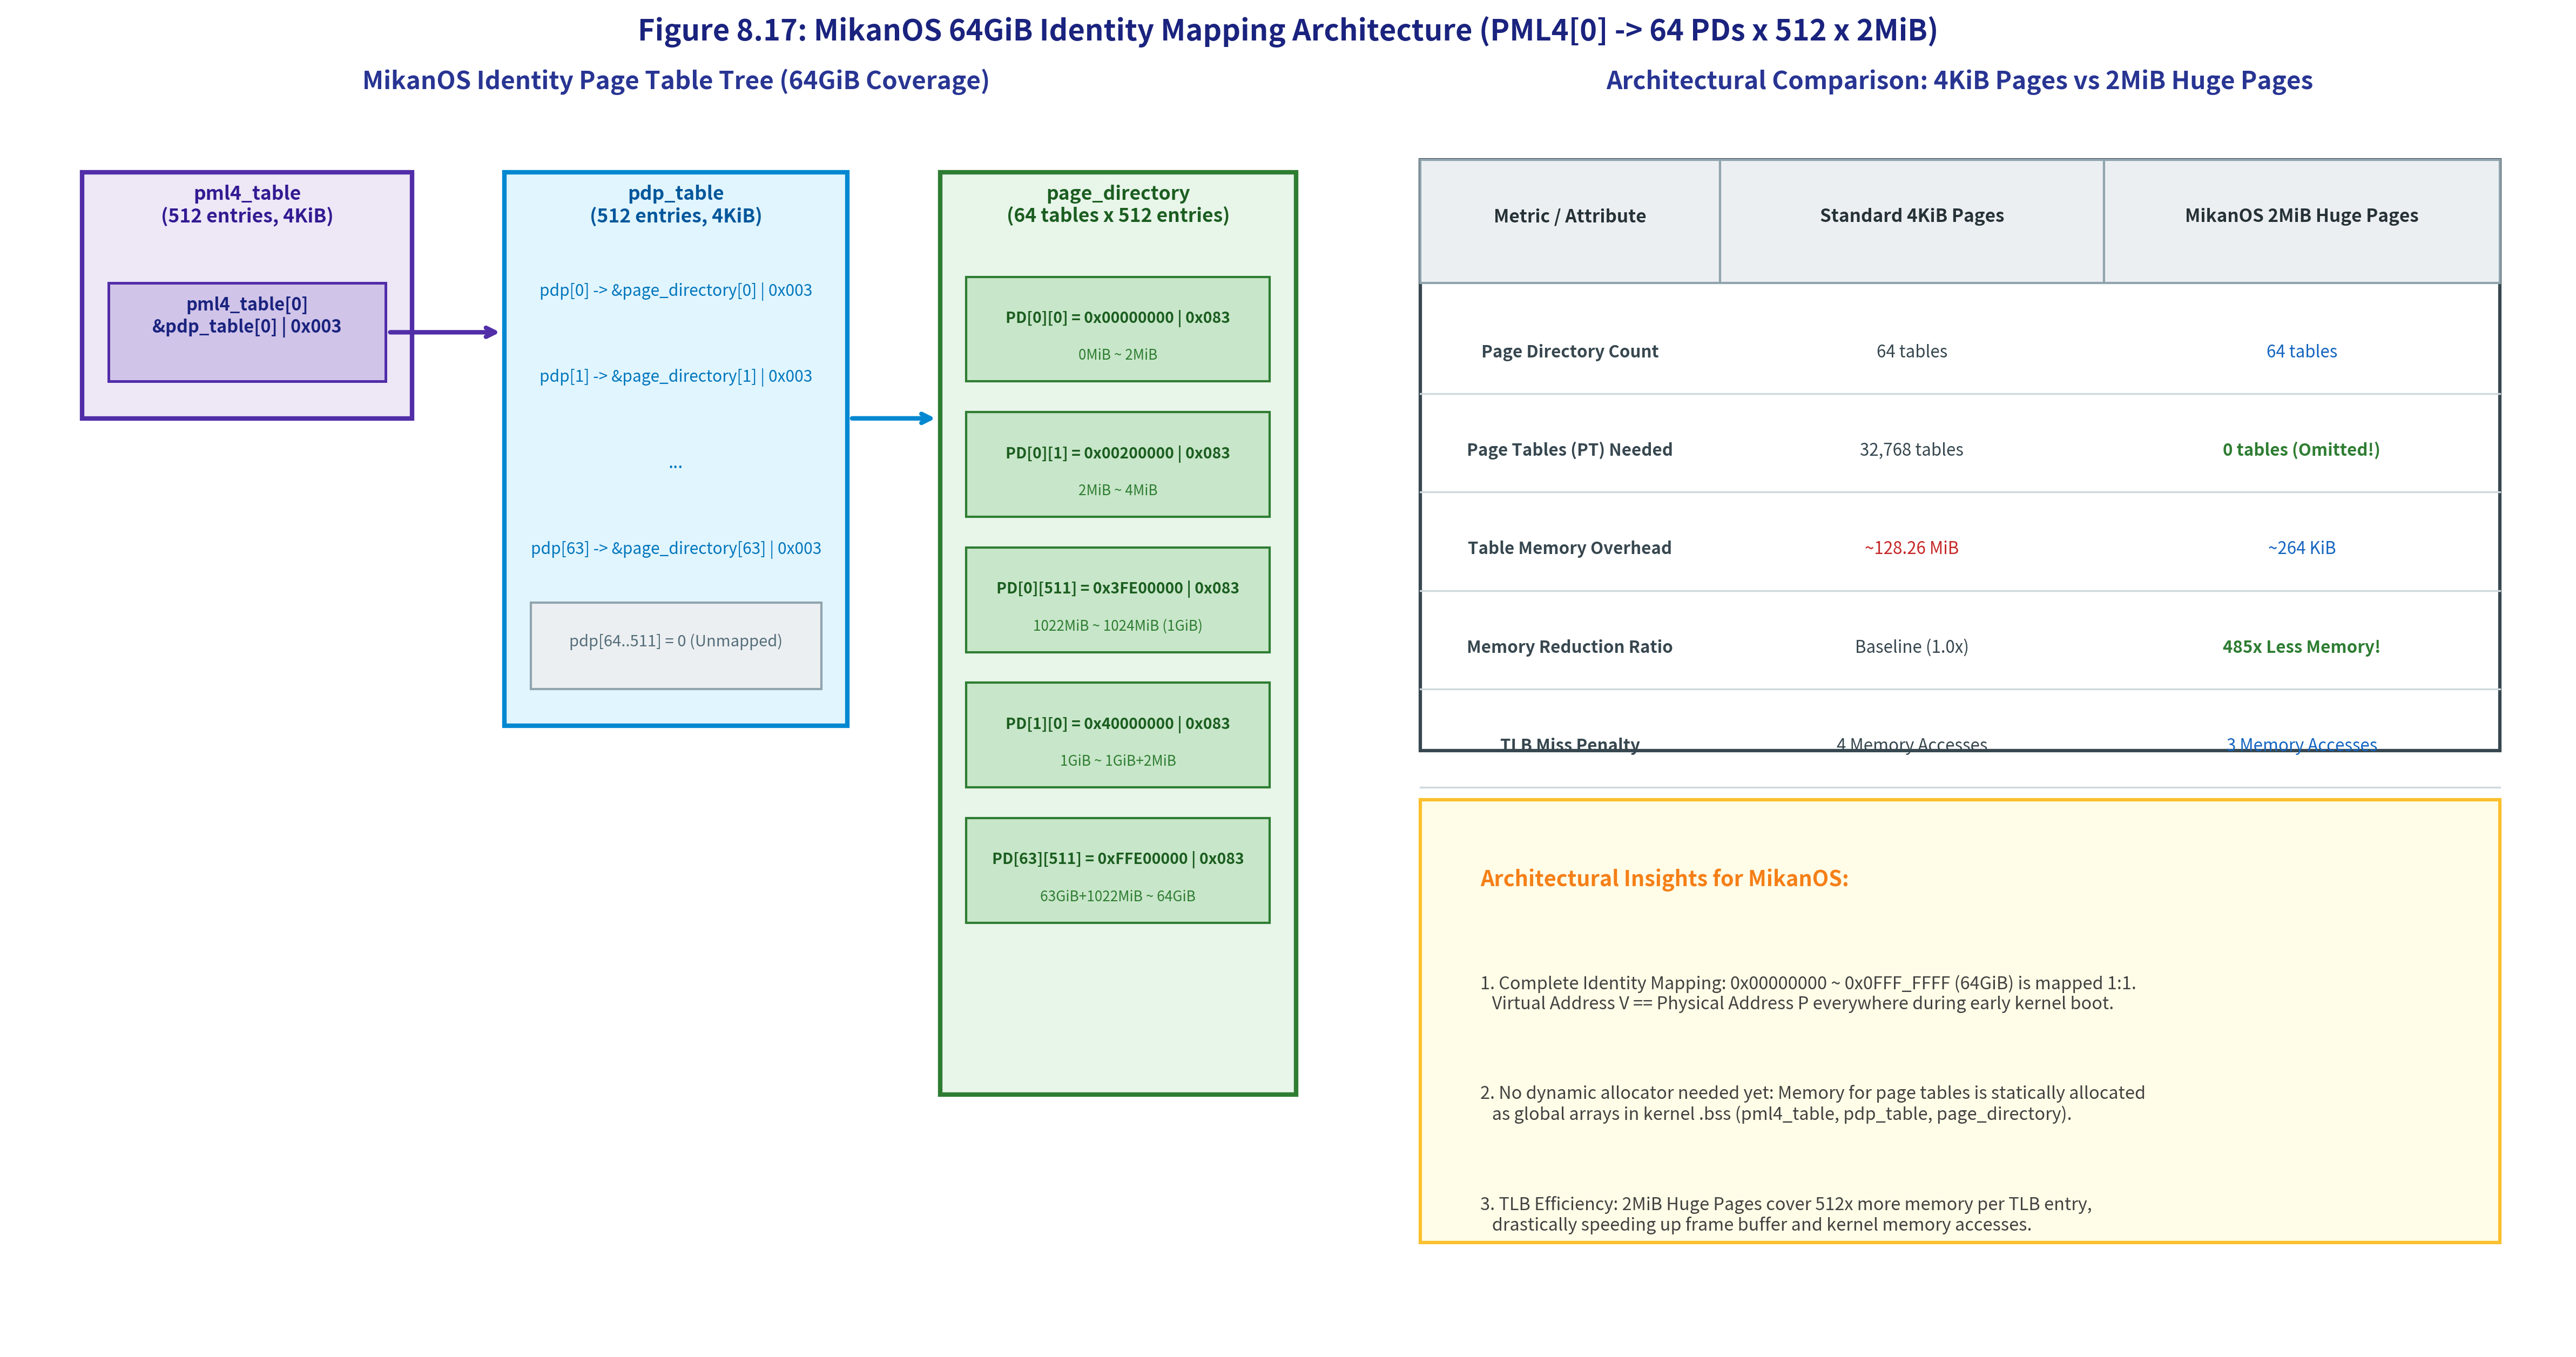

In [3]:
# 図版 8.17: MikanOS 64GiB 恒等マッピングアーキテクチャの生成
from common.os_sim import plot_fig8_17_identity_mapping_2mib_huge_pages
from IPython.display import Image, display

fig8_17_path = plot_fig8_17_identity_mapping_2mib_huge_pages()
display(Image(filename=fig8_17_path))


### 図版 8.17 の解説: テーブルの木構造と 2MiB ページ効率

上図の左パネルは、MikanOS における 64GiB 恒等マッピングの木構造を示しています：
- `pml4_table[0]` のみが使用され、`pdp_table` を指しています（仮想アドレスの 0〜512GiB 範囲を担当）。
- `pdp_table` は 512 エントリ中、先頭 **64 エントリ**（`pdp_table[0..63]`）がそれぞれ 1 個ずつの Page Directory を指しています。残りの 448 エントリは 0（Unmapped）です。
- 64 個の Page Directory は、それぞれ 512 個の 2MiB ページフレーム（計 32,768 エントリ）を等差数列的に 0 番地から 64GiB まで隙間なくマッピングしています。

---

## 4. ページテーブルエントリのフラグ解析と CR3 レジスタ

### 4.1 フラグ `0x003` と `0x083` の数理的導出
MikanOS の `SetupIdentityPageTable()` に登場するマジックナンバー `0x003` と `0x083` は、x86-64 ページテーブルエントリのビット定義から完全に導出されます：

| ビット | フラグ名 | 意味 | `0x003` (PML4E / PDPTE) | `0x083` (2MiB PDE) |
|:---:|:---|:---|:---:|:---:|
| **0** | **P** (*Present*) | ページまたは次層テーブルが存在する（1 で有効） | **`1`** | **`1`** |
| **1** | **R/W** (*Read/Write*) | 読み書き可能（1 で Read/Write、0 で Read-Only） | **`1`** | **`1`** |
| **2** | **U/S** (*User/Supervisor*) | 特権レベル（0 で Ring 0 カーネル専用、1 で Ring 3 許可） | `0` (Kernel) | `0` (Kernel) |
| **3** | **PWT** (*Page-level Write-Through*) | ライトスルーキャッシュ制御 | `0` | `0` |
| **4** | **PCD** (*Page-level Cache Disable*) | キャッシュ無効化 | `0` | `0` |
| **5** | **A** (*Accessed*) | CPU がアクセスした際に自動セット | `0` | `0` |
| **6** | **D** (*Dirty*) | 書き込み発生時に自動セット | `0` | `0` |
| **7** | **PS** (*Page Size*) | **0: 次階層テーブルを参照, 1: Huge Page (2MiB / 1GiB)** | **`0`** | **`1` (2MiB Page)** |

- **`0x003` の導出**:
  $$\text{Bit } 0 \;(P=1) \;|\; \text{Bit } 1 \;(R/W=1) = 0b0000\_0011 = \mathbf{0x003}$$
  PML4 および PDP エントリは下位テーブルを指すポインタであるため、`PS = 0` でなければなりません。
- **`0x083` の導出**:
  $$\text{Bit } 0 \;(P=1) \;|\; \text{Bit } 1 \;(R/W=1) \;|\; \text{Bit } 7 \;(PS=1) = 0b1000\_0011 = \mathbf{0x083}$$
  Page Directory エントリは PT をスキップして 2MiB 物理フレームを直接指すため、`PS = 1`（ビット 7）をセットします。

### 4.2 4KiB アライメント制約（`alignas(4096)`）の理由
テーブルのベースアドレスがなぜ 4096 バイト境界（下位 12 ビットがすべて `0`）でなければならないのか？
その答えは、**エントリの下位 12 ビットが属性フラグ（P, R/W, U/S, PS 等）として使われるため**です。
アドレスの下位 12 ビットが常に 0 であることによって、アドレスとフラグを単純なビット論理和（`Address | Flags`）で合成し、CPU はビット論理積（`Entry & ~0xFFF`）でアドレス部分だけをノーコストで抽出できるのです。

### 4.3 CR3 レジスタと TLB フラッシュ
CR3 レジスタ（*Control Register 3*, PDBR）は、PML4 テーブルの先頭物理アドレスを保持します。
x86 CPU は、**CR3 レジスタに新しい値をロード（`MOV CR3, RDI`）した瞬間に、CPU 内部のアドレス変換キャッシュである TLB (*Translation Lookaside Buffer*) を自動的に全クリア（フラッシュ）**します（Global フラグが付与されたエントリを除く）。
これにより、古い UEFI の変換キャッシュが消去され、直ちに自前のページテーブルに従ってアドレス変換が行われます。


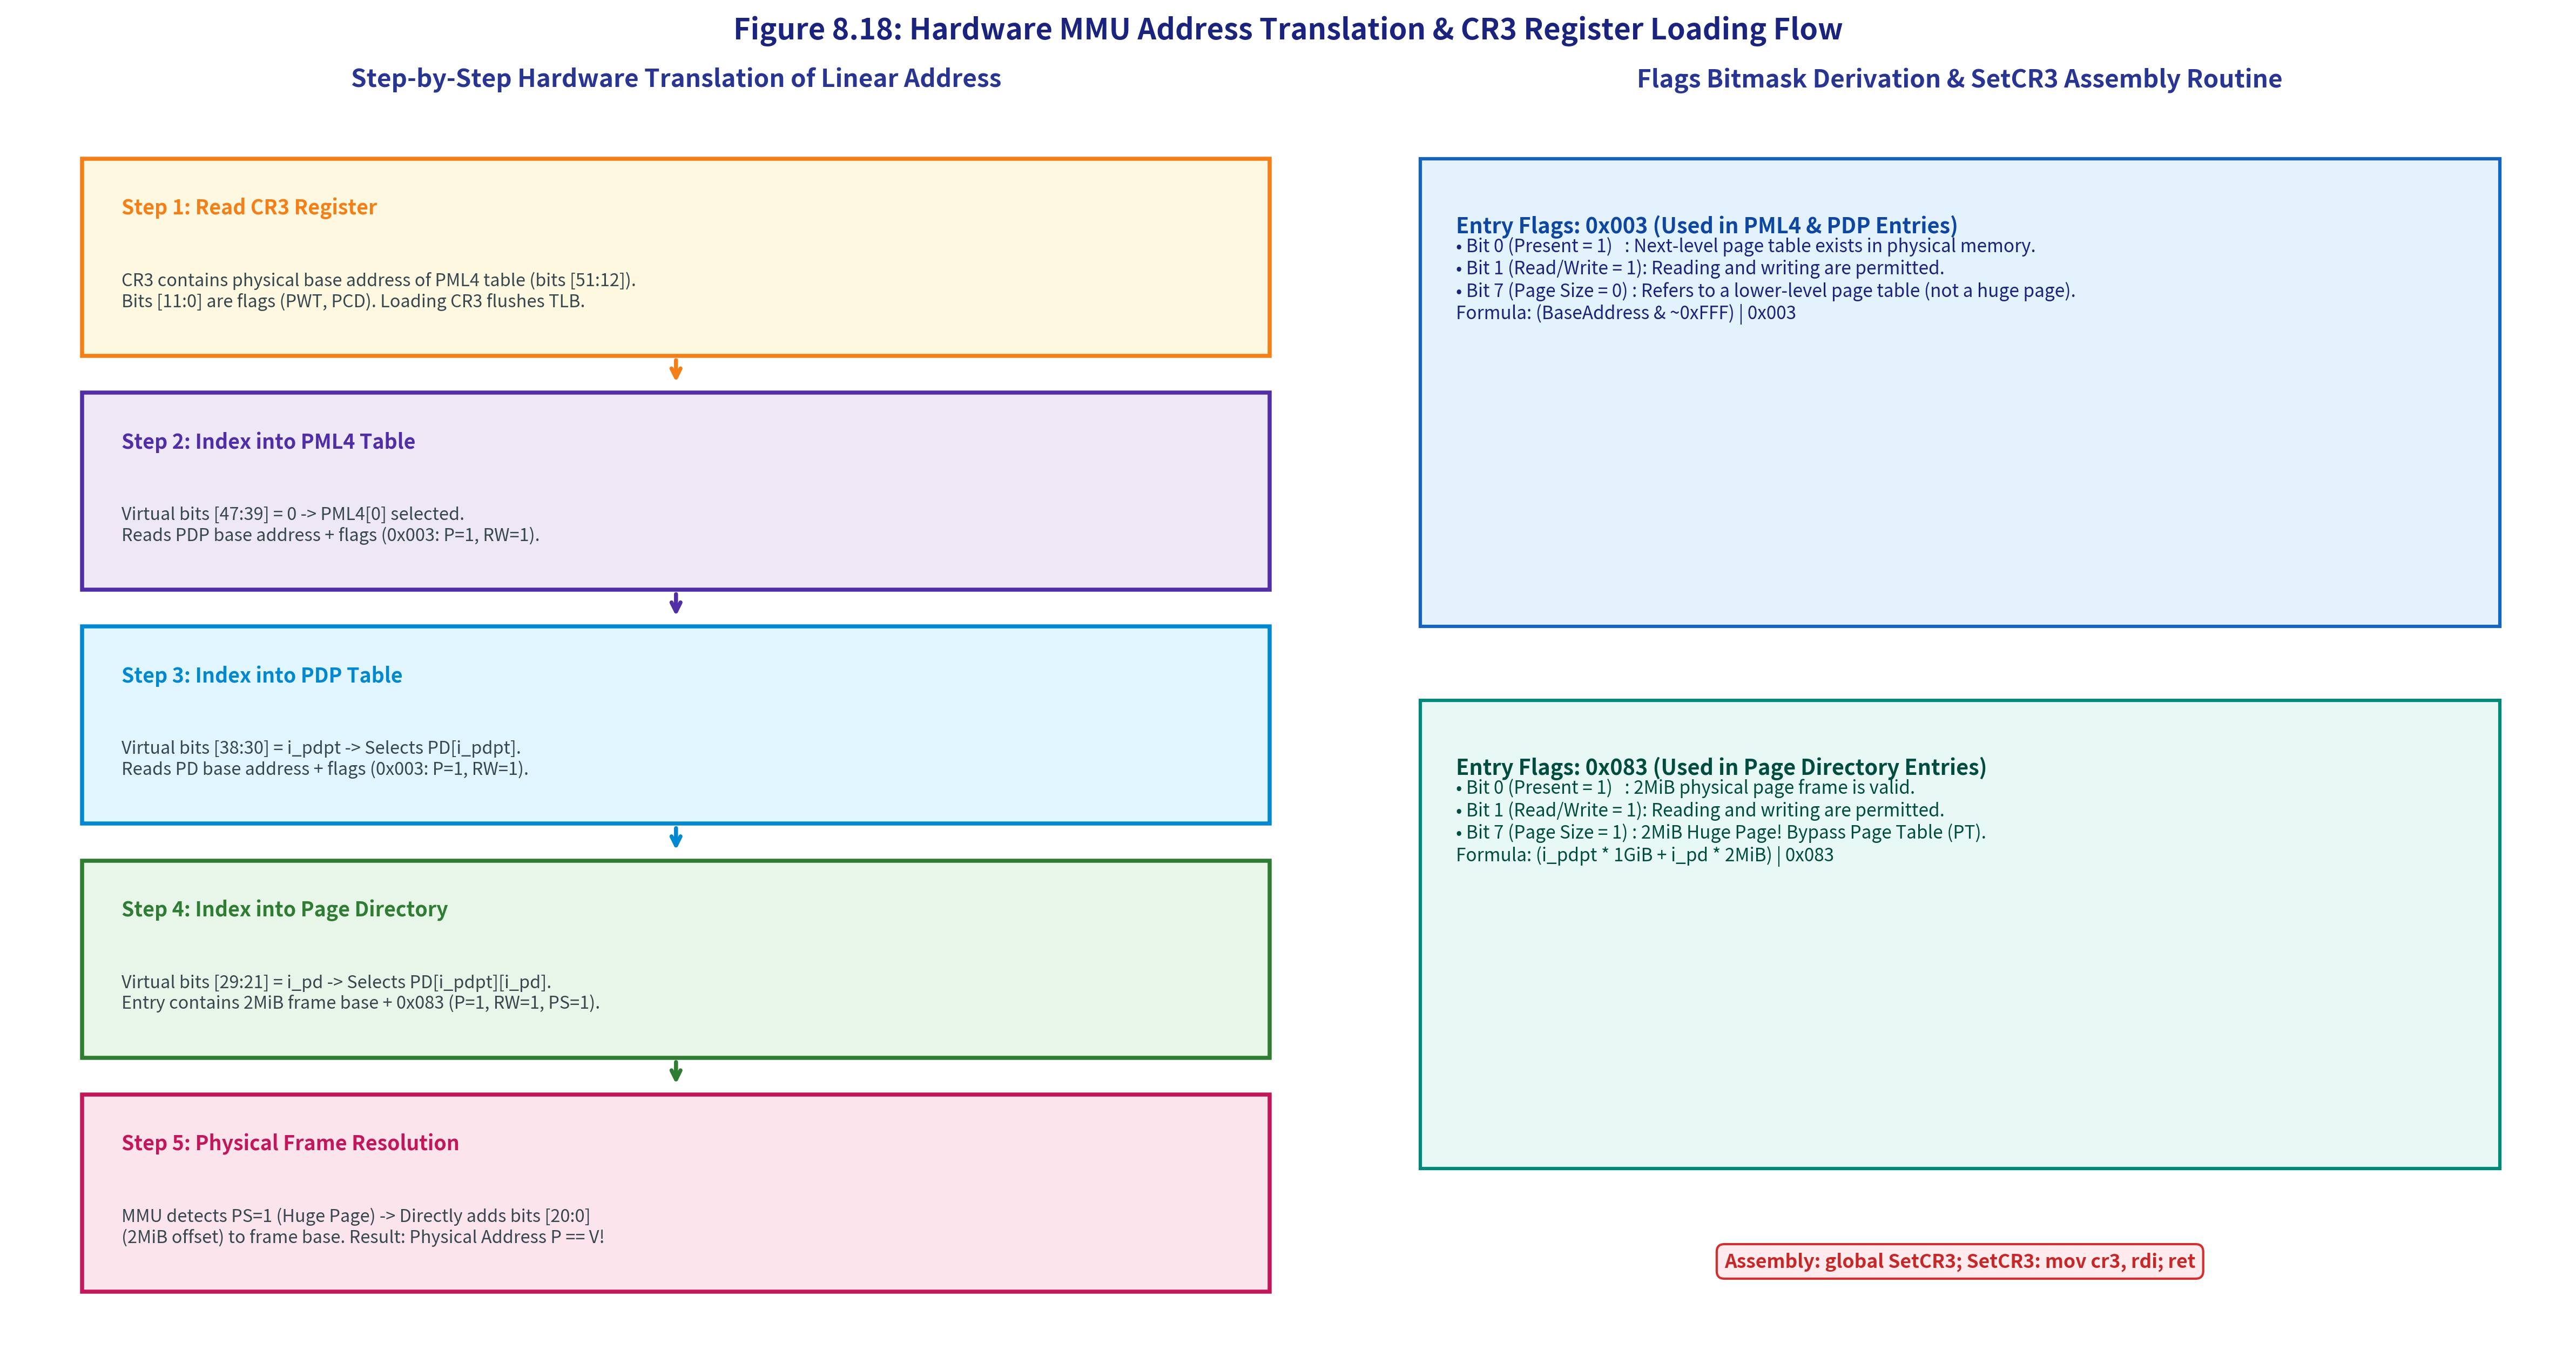

In [4]:
# 図版 8.18: ハードウェア MMU アドレス変換と CR3 レジスタ設定フローの生成
from common.os_sim import plot_fig8_18_cr3_and_address_translation_flow
from IPython.display import Image, display

fig8_18_path = plot_fig8_18_cr3_and_address_translation_flow()
display(Image(filename=fig8_18_path))


### 図版 8.18 の解説: MMU の 2MiB ページ解決ステップ

仮想アドレス（例: `0x0000_0001_8020_1234`）が CPU に与えられると、MMU は以下の手順で瞬時に物理アドレスを特定します：

1. `CR3` レジスタから PML4 テーブルの物理ベースアドレスを取得。
2. 仮想アドレスの `[47:39]` (PML4 インデックス: `0`) を参照 $\rightarrow$ `pml4_table[0]` から PDP テーブルアドレスを取得。
3. 仮想アドレスの `[38:30]` (PDP インデックス: `6`) を参照 $\rightarrow$ `pdp_table[6]` から 6 番目の Page Directory アドレスを取得。
4. 仮想アドレスの `[29:21]` (PD インデックス: `1`) を参照 $\rightarrow$ `page_directory[6][1]` から 2MiB フレームベースを取得。
5. エントリのビット 7（`PS = 1`）を確認し、PT 探索を行わずに仮想アドレスの下位 21 ビット（`[20:0]` オフセット: `0x0020_1234`）を加算。
6. 物理アドレス `0x0000_0001_8020_1234` が決定され、DRAM へアクセス！


---

## 5. MikanOS 実装コードの完全行単位解説

MikanOS 公式リポジトリの `kernel/paging.hpp`, `kernel/paging.cpp`, `kernel/asmfunc.asm`, `kernel/main.cpp` におけるページング実装を精読します。

### 5.1 `kernel/paging.hpp`
```cpp
#pragma once
#include <cstddef>

// 静的に確保するページディレクトリの個数 (64 個 x 1GiB = 64GiB)
const size_t kPageDirectoryCount = 64;

// 仮想アドレス = 物理アドレスとなるようにページテーブルを設定し、CR3 に登録する
void SetupIdentityPageTable();
```

### 5.2 `kernel/paging.cpp`
```cpp
#include "paging.hpp"
#include <array>
#include "asmfunc.h"

namespace {
  const uint64_t kPageSize4K = 4096;
  const uint64_t kPageSize2M = 512 * kPageSize4K; // 2MiB
  const uint64_t kPageSize1G = 512 * kPageSize2M; // 1GiB

  // 各テーブルは 4KiB 境界に配置されなければならない (alignas(kPageSize4K))
  alignas(kPageSize4K) std::array<uint64_t, 512> pml4_table;
  alignas(kPageSize4K) std::array<uint64_t, 512> pdp_table;
  alignas(kPageSize4K)
    std::array<std::array<uint64_t, 512>, kPageDirectoryCount> page_directory;
}

void SetupIdentityPageTable() {
  // PML4 の 0 番エントリに pdp_table の先頭アドレスを書き込む (0x003: Present | Read/Write)
  pml4_table[0] = reinterpret_cast<uint64_t>(&pdp_table[0]) | 0x003;

  for (int i_pdpt = 0; i_pdpt < page_directory.size(); ++i_pdpt) {
    // PDP の各エントリに各 page_directory の先頭アドレスを書き込む
    pdp_table[i_pdpt] = reinterpret_cast<uint64_t>(&page_directory[i_pdpt]) | 0x003;

    for (int i_pd = 0; i_pd < 512; ++i_pd) {
      // 物理アドレス: i_pdpt * 1GiB + i_pd * 2MiB
      // 0x083: Present (0x1) | Read/Write (0x2) | Page Size 2MiB (0x80)
      page_directory[i_pdpt][i_pd] = i_pdpt * kPageSize1G + i_pd * kPageSize2M | 0x083;
    }
  }

  // PML4 テーブルの物理アドレスを CR3 レジスタに書き込んでページングを切り替える
  SetCR3(reinterpret_cast<uint64_t>(&pml4_table[0]));
}
```

### 5.3 `kernel/asmfunc.asm`
```nasm
global SetCR3  ; void SetCR3(uint64_t value);
SetCR3:
    mov cr3, rdi   ; 第1引数 (RDI) を CR3 レジスタへ直接書き込む
    ret            ; 即座に新しいページテーブルで命令実行が継続される
```

### 5.4 `kernel/main.cpp` での初期化シーケンス
前節で実装したセグメンテーション（GDT）設定に続いて、ページングが呼び出されます：
```cpp
  SetupSegments();

  const uint16_t kernel_cs = 1 << 3;
  SetDSAll(0);
  SetCS(kernel_cs);

  SetupIdentityPageTable(); // 自前の 64GiB 恒等ページテーブルを CR3 にロード！
```
この 1 行が完了した瞬間、MikanOS カーネルは UEFI のページテーブルから完全に独立し、自律した仮想記憶管理下で動作する真の OS へと進化します。


In [5]:
# C++20 ページングシミュレータのコンパイルと単体テスト実行
import subprocess
import os

cpp_source = "src/ch08/identity_paging_sim.cpp"
bin_dir = "build/bin"
bin_path = os.path.join(bin_dir, "ch08_identity_paging_sim")

os.makedirs(bin_dir, exist_ok=True)

# g++ で C++20 最適化コンパイル
compile_cmd = ["g++", "-std=c++20", "-O2", "-Wall", "-Wextra", cpp_source, "-o", bin_path]
print("Compiling C++20 simulator:", " ".join(compile_cmd))
subprocess.run(compile_cmd, check=True)

# 1. デモ実行（サンプルアドレス変換一覧）
print("\n=== C++20 Simulator Output ===")
res_demo = subprocess.run([bin_path], capture_output=True, text=True, check=True)
print(res_demo.stdout)

# 2. 単体テスト実行 (--test)
print("=== Running C++20 Verification Unit Tests ===")
res_test = subprocess.run([bin_path, "--test"], capture_output=True, text=True, check=True)
print(res_test.stdout)


Compiling C++20 simulator: g++ -std=c++20 -O2 -Wall -Wextra src/ch08/identity_paging_sim.cpp -o build/bin/ch08_identity_paging_sim



=== C++20 Simulator Output ===

  MikanOS Chapter 8.6: Identity Paging & 4-Level Paging Architecture
Configuration Summary:
  PML4 Table Address: 0x7ffec1e7a000
  PDP Table Address : 0x7ffec1e7b000
  PD Count          : 64 tables
  Total Mapped Space: 64 GiB
  CR3 Register      : 0x7ffec1e7a000

Sample Translations across 64GiB Address Space:
  Virtual: 0x0000000000 -> Physical: 0x0000000000 [PML4:0, PDP:0, PD:0, Off2M: 0x0] (Identity: MATCH)
  Virtual: 0x0000100000 -> Physical: 0x0000100000 [PML4:0, PDP:0, PD:0, Off2M: 0x100000] (Identity: MATCH)
  Virtual: 0x0000200000 -> Physical: 0x0000200000 [PML4:0, PDP:0, PD:1, Off2M: 0x0] (Identity: MATCH)
  Virtual: 0x0040000000 -> Physical: 0x0040000000 [PML4:0, PDP:1, PD:0, Off2M: 0x0] (Identity: MATCH)
  Virtual: 0x0080000000 -> Physical: 0x0080000000 [PML4:0, PDP:2, PD:0, Off2M: 0x0] (Identity: MATCH)
  Virtual: 0x00ffffffff -> Physical: 0x00ffffffff [PML4:0, PDP:3, PD:511, Off2M: 0x1fffff] (Identity: MATCH)
  Virtual: 0x0100000000 -> Phy

In [6]:
# Python による対話型ページングシミュレーションとメモリ節約の定量評価
from common.os_sim import IdentityPagingSimulator, LinearAddress4LevelSim, PageTableEntrySim

sim = IdentityPagingSimulator()

print("=== Python IdentityPagingSimulator 検証 ===")
print(f"CR3 レジスタ値: 0x{sim.cr3:016x}")
print(f"PML4 テーブルベース: 0x{sim.pml4_base:016x}")
print(f"テーブルアライメント検証 (4KiB境界): {sim.verify_table_alignments()}")

# 様々な仮想アドレスのアドレス変換実験
test_addresses = [
    (0x0000_0000, "RAM 先頭"),
    (0x0010_0000, "カーネル配置領域 (1MiB)"),
    (0x0020_0000, "第2の 2MiB ページ先頭"),
    (0x4000_0000, "1GiB 境界 (PDP[1])"),
    (0xFFFF_FFFF, "32ビット空間上限 (4GiB - 1)"),
    (0x1_0000_0000, "4GiB 境界 (PDP[4])"),
    (0xF_FFE0_0000, "64GiB - 2MiB (最終ページ)"),
]

print("\n--- 仮想アドレス -> 物理アドレス 変換結果 ---")
for vaddr, desc in test_addresses:
    res = sim.translate(vaddr)
    print(f"[{desc:20s}] 仮想: 0x{vaddr:010x} -> 物理: 0x{res['physical_address']:010x} "
          f"(PML4:{res['pml4_index']}, PDP:{res['pdp_index']}, PD:{res['pd_index']}) "
          f"一致判定: {res['is_identity']}")

# メモリ削減効果の定量比較
savings = sim.calculate_memory_savings()
print("\n--- 4KiB ページ vs 2MiB Huge Page メモリオーバーヘッド比較 (64GiB マッピング時) ---")
print(f"・標準 4KiB ページ方式の所要メモリ: {savings['4k_page_table_overhead_mib']:.2f} MiB")
print(f"・MikanOS 2MiB ページ方式の所要メモリ: {savings['2m_huge_page_overhead_kib']:.2f} KiB")
print(f"・メモリ消費削減倍率: {savings['memory_reduction_ratio']:.1f} 倍の圧倒的節約！")


=== Python IdentityPagingSimulator 検証 ===
CR3 レジスタ値: 0x0000000010000000
PML4 テーブルベース: 0x0000000010000000
テーブルアライメント検証 (4KiB境界): True

--- 仮想アドレス -> 物理アドレス 変換結果 ---
[RAM 先頭              ] 仮想: 0x0000000000 -> 物理: 0x0000000000 (PML4:0, PDP:0, PD:0) 一致判定: True
[カーネル配置領域 (1MiB)     ] 仮想: 0x0000100000 -> 物理: 0x0000100000 (PML4:0, PDP:0, PD:0) 一致判定: True
[第2の 2MiB ページ先頭      ] 仮想: 0x0000200000 -> 物理: 0x0000200000 (PML4:0, PDP:0, PD:1) 一致判定: True
[1GiB 境界 (PDP[1])    ] 仮想: 0x0040000000 -> 物理: 0x0040000000 (PML4:0, PDP:1, PD:0) 一致判定: True
[32ビット空間上限 (4GiB - 1)] 仮想: 0x00ffffffff -> 物理: 0x00ffffffff (PML4:0, PDP:3, PD:511) 一致判定: True
[4GiB 境界 (PDP[4])    ] 仮想: 0x0100000000 -> 物理: 0x0100000000 (PML4:0, PDP:4, PD:0) 一致判定: True
[64GiB - 2MiB (最終ページ)] 仮想: 0x0fffe00000 -> 物理: 0x0fffe00000 (PML4:0, PDP:63, PD:511) 一致判定: True

--- 4KiB ページ vs 2MiB Huge Page メモリオーバーヘッド比較 (64GiB マッピング時) ---
・標準 4KiB ページ方式の所要メモリ: 128.26 MiB
・MikanOS 2MiB ページ方式の所要メモリ: 264.00 KiB
・メモリ消費削減倍率: 497.5 倍の圧倒的節約！


---

## 6. 実装上の落とし穴とデバッグ指針 (Common Pitfalls & Traps)

低レイヤのページング初期化において初学者が遭遇しやすい致命的なバグと、その対処法を整理します：

### 落とし穴 1: 4KiB アライメント忘れによる `#GP` / `#PF`
- **症状**: `SetCR3` を実行した瞬間、QEMU が再起動（リブート）を繰り返す。
- **原因**: ページテーブル配列に `alignas(4096)` を付け忘れると、コンパイラがテーブルを奇数アドレスや 16 バイト境界に配置してしまうことがあります。CR3 レジスタや上位エントリは「下位 12 ビットが 0 である」ことを前提にポインタとして読み取るため、ゴミ値がアドレスとして解釈され、CPU は存在しないメモリを参照して即死します。
- **対策**: `alignas(kPageSize4K)` をすべてのテーブル配列に必ず明記すること。

### 落とし穴 2: Page Directory での `PS` ビット（ビット 7）設定忘れ
- **症状**: 仮想アドレス `0x100000` にアクセスした瞬間、ページフォルト（例外 14 番 `#PF`）が発生する。
- **原因**: Page Directory エントリに `0x083` ではなく誤って `0x003` を書き込んでしまうと、CPU は「このエントリは 2MiB ページではなく、Level 1 Page Table (PT) を指すポインタである」と解釈します。しかし PT など確保していないため、物理アドレス `0x0000` 付近のメモリを PT だと誤認して不正アクセスに陥ります。
- **対策**: PD エントリには必ず `0x083`（ビット 7 = 1）をセットすること。

### 落とし穴 3: 符号拡張なしの非正規アドレスアクセス
- **症状**: 将来アプリを上位アドレス空間（`0xFFFF800000000000` など）に配置した際、一般保護例外 `#GP` が発生する。
- **原因**: 48 ビットアドレスのビット 47 が 1 である場合、上位 16 ビット（`[63:48]`）をすべて `0xFFFF` に符号拡張しなければなりません。`0x0000800000000000` のようなアドレスはハードウェア仕様違反です。


---

## 7. まとめと次節への展望

### 本節のまとめ
1. **Long Mode とページングの不可分性**:
   - x86-64 では `CR0.PG = 1` が強制される。UEFI 任せの危険なページテーブルを捨て、カーネル管理下のテーブルへ移行することが OS 自作の最重要関門の一つである。
2. **4階層ページングの数理**:
   - 48ビットリニアアドレスは PML4 (9b) $\rightarrow$ PDP (9b) $\rightarrow$ PD (9b) $\rightarrow$ PT (9b) $\rightarrow$ Offset (12b) に分解され、各テーブルは 512 エントリ（4 KiB 境界）に収まる。
3. **2MiB Huge Page による 64GiB 恒等マッピング**:
   - PD エントリで `PS = 1`（`0x083`）とすることで PT を全廃し、わずか 264 KiB のテーブルで 64GiB の全物理メモリを 1:1 恒等マッピングした。
4. **CR3 ロード**:
   - `SetCR3` により PML4 アドレスを CPU に通知し、同時に TLB キャッシュをリフレッシュした。

### 次節（8.7 メモリ管理に挑戦 / `osbook_day08c`）への展望
ページテーブルによって 64GiB の物理空間が安定してアクセス可能になりました。
しかし、OS がカーネルやアプリケーションにメモリを動的に貸し出すためには、**「どの 4KiB ページフレームが空いていて、どれが使用中なのか」**をビット単位で追跡・割り当て・解放する仕組みが必要です。
次節では、MikanOS の中核メモリアロケータである **`BitmapMemoryManager`（ビットマップメモリマネージャ）**の実装と検証に挑戦します！
